# 03 — Exogenous Features

Sales history tells us what happened, but additional information can help us understand why demand changes.

A retailer may know its upcoming prices and promotions, while a manufacturer forecasting retail sales may only have access to historical information. The features we build depend on what information is available when we generate the forecast.

In this notebook, we extend our global LightGBM model with price and promotion features.

1. Understand the business and available data.
2. Engineer price features.
3. Engineer promotion features.
4. Forecast with and without future driver information.
5. Evaluate the incremental value of these features.
6. Explore how forecasts respond to changes in price.

**Assumption:** Historical versions of pricing and promotion plans are not available in this dataset. We use recorded prices and promotions as proxies for future plans where appropriate. Results using these inputs represent conditional forecasts, not necessarily achievable production accuracy.

We keep the model configuration from Notebook 02 unchanged so that we can isolate the impact of adding exogenous features.

In [193]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [194]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS, CATEGORICAL, item_attributes, partial_plan
from shared.evaluation import score
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard, breakdown

# The shared feature functions are used only to check that the feature code written out below matches them.
from shared.features import add_drivers, future_drivers, historical_drivers, realized_drivers

## Notebook walkthrough

| Topic | What we'll explore |
|---|---|
| Data and drivers | Understand the price and promotion data. |
| Price features | Engineer features that capture pricing and discount behavior. |
| Promotion features | Engineer features that capture promotion timing and demand response. |
| Future-driver visibility | Incorporate known future prices and promotions using `X_df`. |
| Historical drivers | Build features when future prices and promotions are unavailable. |
| Model evaluation | Compare the incremental value of each feature group across backtesting windows. |
| Products and scenarios | Explore individual forecasts and how they respond to price changes. |
| Information availability | Understand potential leakage and realistic forecasting assumptions. |

## 2. Data and the standard model configuration

One row per product and week. Three raw columns describe the drivers:

- `regular_price`: the shelf price;
- `sale_price`: the average price paid in the week, computed from the week's transactions;
- `is_promotional`: whether the product was on promotion that week.

In [254]:
panel = load_panel()
actuals = panel[["unique_id", "ds", "y"]]
attributes = item_attributes(panel)          # department, class and subclass of each product

print(f"{panel.unique_id.nunique():,} products, {panel.ds.nunique()} weeks, {panel.ds.min():%Y-%m-%d} to {panel.ds.max():%Y-%m-%d}")


2,000 products, 107 weeks, 2023-07-05 to 2025-07-16


In [196]:
panel[[
    "unique_id",
    "item_id",
    "item_desc",
    "department_name",
    "class_name",
    "subclass_name",
    "ds",
    "y",
    "regular_price",
    "sale_price",
    "is_promotional"
]].head()

,unique_id,item_id,item_desc,department_name,class_name,subclass_name,ds,y,regular_price,sale_price,is_promotional
0,10006_S1,10006,Tuna garlic and chilli 95g,Canned Seafood,Tuna,Tuna Small Can (<=95g),2023-07-05,890.0,2.95,2.917978,False
1,10006_S1,10006,Tuna garlic and chilli 95g,Canned Seafood,Tuna,Tuna Small Can (<=95g),2023-07-12,1110.0,2.95,2.933694,False
2,10006_S1,10006,Tuna garlic and chilli 95g,Canned Seafood,Tuna,Tuna Small Can (<=95g),2023-07-19,940.0,2.95,2.934681,False
3,10006_S1,10006,Tuna garlic and chilli 95g,Canned Seafood,Tuna,Tuna Small Can (<=95g),2023-07-26,1020.0,2.95,2.922157,False
4,10006_S1,10006,Tuna garlic and chilli 95g,Canned Seafood,Tuna,Tuna Small Can (<=95g),2023-08-02,1070.0,2.95,2.924299,False


The model configuration comes from notebook 02 and is not redefined here: lags, rolling means, calendar terms and LightGBM parameters.

In [197]:
print("lags:", LAGS)
print("rolling means on lag 1:", [t.__class__.__name__ + str(t.window_size) for t in LAG_TRANSFORMS[1]])
LGB_PARAMS

lags: [1, 2, 3, 4, 8, 13]
rolling means on lag 1: ['RollingMean4', 'RollingMean13', 'RollingMean26']


{'n_estimators': 300,
 'learning_rate': 0.05,
 'num_leaves': 31,
 'min_child_samples': 50,
 'subsample': 0.8,
 'subsample_freq': 1,
 'colsample_bytree': 0.8,
 'random_state': 0,
 'verbosity': -1}

## 3. Understanding the Price and Promotion Drivers

Before engineering our exogenous features, let's investigate the historical relationships between pricing, promotions and sales.

We use observations through the final training cutoff for this analysis. When forecasting, we will assume future pricing and promotional plans are available, using realized values as proxies where appropriate.

### Price levels differ across products

A global model learns across products with very different price levels. A $1 discount on a $3 product represents a much larger relative discount than a $1 discount on a $20 product.

By engineering relative price and discount features, we give the model additional context about how a product is priced relative to its normal selling price.

Both absolute and relative prices may provide useful information. We will evaluate their incremental value in our forecasting experiments.

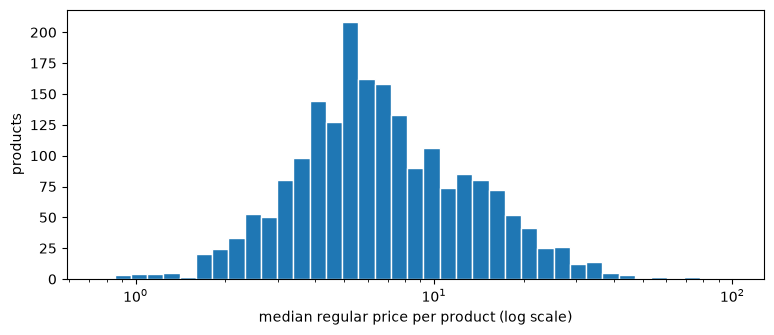

count    2000.00
mean        8.54
std         7.19
min         0.75
5%          2.40
50%         6.20
95%        22.00
max       100.00
Name: regular_price, dtype: float64

In [198]:
past = panel[panel.ds <= TEST_CUTOFF].copy()
median_regular_price = past.groupby("unique_id").regular_price.median()

fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.geomspace(median_regular_price.min(), median_regular_price.max(), 40)
ax.hist(median_regular_price, bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.set(xlabel="median regular price per product (log scale)", ylabel="products")
plt.show()

median_regular_price.describe(percentiles=[0.05, 0.5, 0.95]).round(2)

### Two products over time

A frequently promoted product and one that is rarely promoted, both among the top third by sales. Top: weekly sales. Middle: regular price and the average selling price. Bottom: promotion weeks.

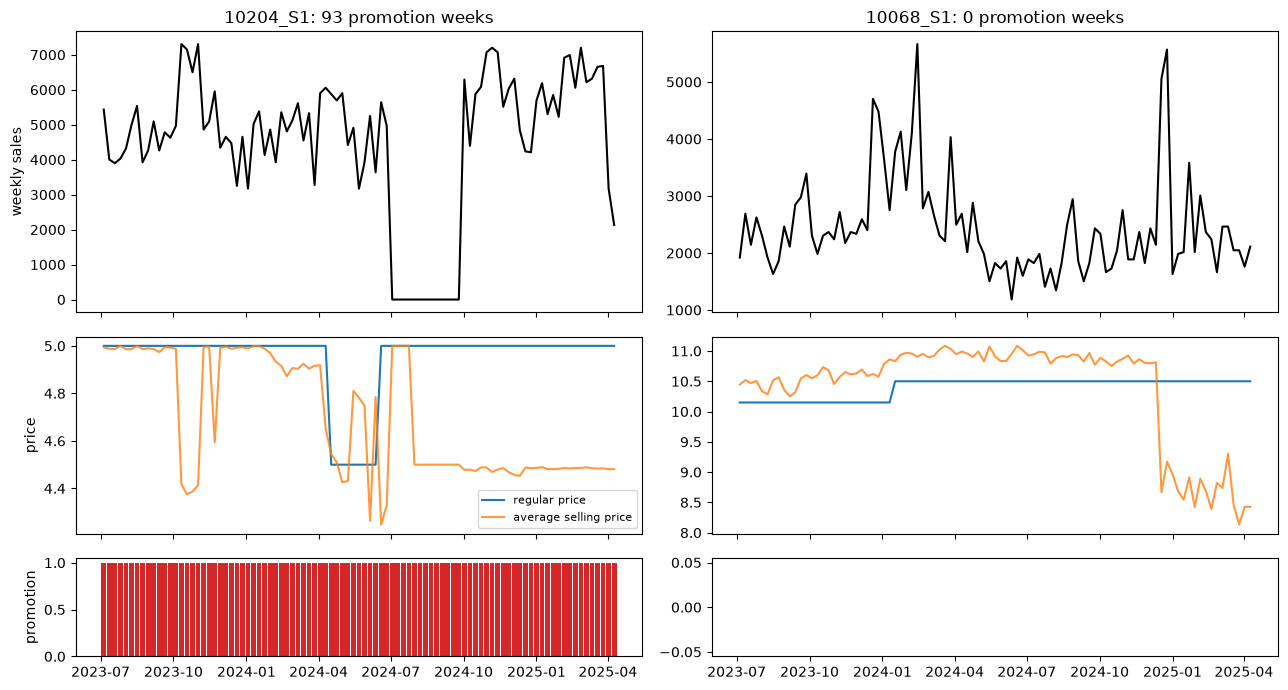

In [199]:
volume = past.groupby("unique_id").y.mean()
promo_weeks_per_product = past.groupby("unique_id").is_promotional.sum()
high_volume = volume[volume >= volume.quantile(2 / 3)].index

often_promoted = promo_weeks_per_product[high_volume].idxmax()
rarely_promoted = promo_weeks_per_product[high_volume].idxmin()

fig, axes = plt.subplots(3, 2, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1.4, 0.7]})
for column, product in enumerate([often_promoted, rarely_promoted]):
    weeks = past[past.unique_id == product]
    axes[0, column].plot(weeks.ds, weeks.y, color="black")
    axes[0, column].set_title(f"{product}: {int(promo_weeks_per_product[product])} promotion weeks")
    axes[1, column].plot(weeks.ds, weeks.regular_price, label="regular price")
    axes[1, column].plot(weeks.ds, weeks.sale_price, label="average selling price", alpha=0.8)
    axes[2, column].bar(weeks.ds, weeks.is_promotional.astype(int), width=6, color="tab:red")
axes[0, 0].set_ylabel("weekly sales")
axes[1, 0].set_ylabel("price")
axes[2, 0].set_ylabel("promotion")
axes[1, 0].legend(fontsize=8)
plt.tight_layout()

The selling price drops in promotion weeks, which is the promotional discount. It also moves around the regular price in ordinary weeks: it is an average over the week's transactions, so it changes with the mix of what sold. Optional section 12 shows why that matters.

In [200]:
hist = panel[panel["ds"] <= TEST_CUTOFF].copy()
hist["discount_pct"] = (
    1 - hist["sale_price"] / hist["regular_price"]
)
hist["has_discount"] = hist["discount_pct"] > 0.01
pd.crosstab(
    hist["is_promotional"],
    hist["has_discount"],
    normalize="index"
).round(3)

has_discount,False,True
is_promotional,,
False,0.724,0.276
True,0.047,0.953


In [201]:
promo_frequency = hist.groupby("unique_id")["is_promotional"].mean()
print("Always promotional:", (promo_frequency == 1).sum())
print("Never promotional:", (promo_frequency == 0).sum())
print("Sometimes promotional:", promo_frequency.between(
    0, 1, inclusive="neither"
).sum())

Always promotional: 78
Never promotional: 567
Sometimes promotional: 1355


## 4. Price features

Five price features, each written out here. `add_drivers` in `shared/features.py` builds the same columns for the later notebooks; a check at the end of the section confirms they match.

Shifts and rolling windows below run within each product, so the panel must be in product and week order.

In [202]:
panel = panel.sort_values(["unique_id", "ds"]).reset_index(drop=True)

### Relative selling price

The average selling price over the regular price: 1 means the product sold at its shelf price, 0.8 means 20% below it. It is on the same scale for every product, so a global model can compare a 2.00 product with a 40.00 one.

A missing or zero regular price would divide by zero; those weeks count as selling at the regular price (ratio 1). Ratios are clipped to [0, 3], which removes a handful of extreme values from data errors.

In [203]:
valid_regular_price = panel.regular_price.where(panel.regular_price > 0)
panel["rel_price"] = (panel.sale_price / valid_regular_price).fillna(1).clip(0, 3)
panel.head()

,unique_id,ds,y,is_promotional,sale_price,regular_price,days_in_week,sale_class,has_any_promo,n_promo_weeks,...,division_id,department_id,class_id,subclass_id,item_group_id,is_delisted,subclass_name,class_name,department_name,rel_price
0,10006_S1,2023-07-05,890.0,False,2.917978,2.95,70,J,True,15,...,16,108.0,117.0,1394.0,18,False,Tuna Small Can (<=95g),Tuna,Canned Seafood,0.989145
1,10006_S1,2023-07-12,1110.0,False,2.933694,2.95,70,J,True,15,...,16,108.0,117.0,1394.0,18,False,Tuna Small Can (<=95g),Tuna,Canned Seafood,0.994472
2,10006_S1,2023-07-19,940.0,False,2.934681,2.95,70,J,True,15,...,16,108.0,117.0,1394.0,18,False,Tuna Small Can (<=95g),Tuna,Canned Seafood,0.994807
3,10006_S1,2023-07-26,1020.0,False,2.922157,2.95,70,J,True,15,...,16,108.0,117.0,1394.0,18,False,Tuna Small Can (<=95g),Tuna,Canned Seafood,0.990562
4,10006_S1,2023-08-02,1070.0,False,2.924299,2.95,70,J,True,15,...,16,108.0,117.0,1394.0,18,False,Tuna Small Can (<=95g),Tuna,Canned Seafood,0.991288


### Discount depth

The promotional discount, `1 - relative price` AND is on promotion, and 0 in every other week. Outside promotions the average selling price drifts around the regular price for reasons that are not a plan (the mix of transactions, and the default described in optional section 12), so it is not treated as a discount.

A selling price above the regular price gives a negative value, clipped to 0. Discounts above 90% are clipped to 90%; they are almost certainly recording errors.

In [204]:
panel["promo"] = panel.is_promotional.astype(int)
panel["discount"] = ((1 - panel.rel_price) * panel.promo).clip(0, 0.9)
panel.tail()

,unique_id,ds,y,is_promotional,sale_price,regular_price,days_in_week,sale_class,has_any_promo,n_promo_weeks,...,class_id,subclass_id,item_group_id,is_delisted,subclass_name,class_name,department_name,rel_price,promo,discount
213295,9985_S1,2025-06-18,1148.0,False,3.946707,4.5,49,J,True,31,...,216.0,1021.0,1452,False,Adult Snacking Cheese,Snacking Cheese,Cheese,0.877046,0,0.000000
213296,9985_S1,2025-06-25,1799.0,True,3.477043,4.5,49,J,True,31,...,216.0,1021.0,1452,False,Adult Snacking Cheese,Snacking Cheese,Cheese,0.772676,1,0.227324
213297,9985_S1,2025-07-02,889.0,False,4.491969,4.5,49,J,True,31,...,216.0,1021.0,1452,False,Adult Snacking Cheese,Snacking Cheese,Cheese,0.998215,0,0.000000
213298,9985_S1,2025-07-09,987.0,False,4.361277,4.5,49,J,True,31,...,216.0,1021.0,1452,False,Adult Snacking Cheese,Snacking Cheese,Cheese,0.969173,0,0.000000
213299,9985_S1,2025-07-16,1134.0,False,4.233025,4.5,49,J,True,31,...,216.0,1021.0,1452,False,Adult Snacking Cheese,Snacking Cheese,Cheese,0.940672,0,0.000000


- A promotional flag does not necessarily indicate a temporary reduction in price. Some products remain flagged as promotional for extended periods, even when their selling price remains unchanged.

- One approach commonly used in demand forecasting is to require both a promotional flag and a minimum discount threshold. Applying a 10% minimum discount threshold reclassifies approximately 21% of our promotional observations.

We tested this alternative definition and found only marginal improvements in forecast accuracy. Because our LightGBM model already receives both the promotional flag and continuous discount depth, it can potentially learn similar relationships without an explicit business rule.

This illustrates an important distinction: improving the business interpretation of a feature does not necessarily improve its predictive value.

### Planned selling price

What the product is planned to sell for: the regular price less the promotional discount. Outside promotions it equals the regular price.

- When Promo = 0  -> Planning price equals regular price
- When Promo = 1  -> Planning price equals sale price unless capping of discount kicked in.

- Attempts to remove the noise of weekly fluctuation in price

In [205]:
panel["planned_price"] = panel.regular_price * (1 - panel.discount)

### Historical Reference Price

Discount depth tells us how much cheaper a product is relative to its current regular price. However, regular prices themselves can change over time.

To capture longer-term price changes, we calculate a historical reference price using the median regular price over a 52-week rolling window.

We lag this window by our 14-week forecast horizon so that the reference price can be calculated without requiring future price observations.

In [206]:
regular_by_product = panel.groupby("unique_id").regular_price
reference = regular_by_product.transform(lambda prices: prices.shift(H).rolling(52, min_periods=1).median())
first_regular_price = regular_by_product.transform("first")
panel["price_reference"] = reference.fillna(first_regular_price)

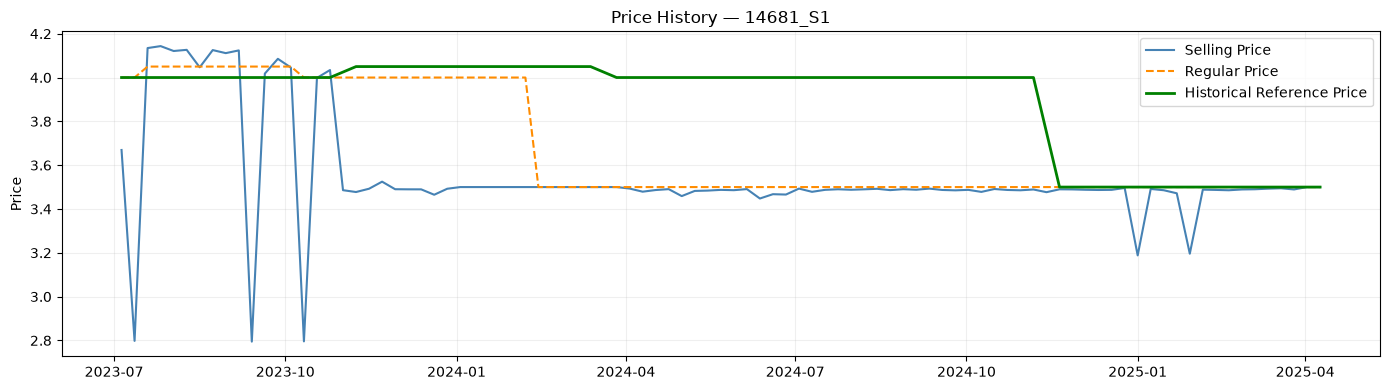

In [207]:
sku = "14681_S1"

product = panel.loc[
    (panel["unique_id"] == sku) &
    (panel["ds"] <= TEST_CUTOFF)
].sort_values("ds")

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(product.ds, product.sale_price,
        label="Selling Price", color="steelblue")

ax.plot(product.ds, product.regular_price,
        label="Regular Price", color="darkorange",
        linestyle="--")

ax.plot(product.ds, product.price_reference,
        label="Historical Reference Price", color="green",
        linewidth=2)

ax.set_title(f"Price History — {sku}")
ax.set_ylabel("Price")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

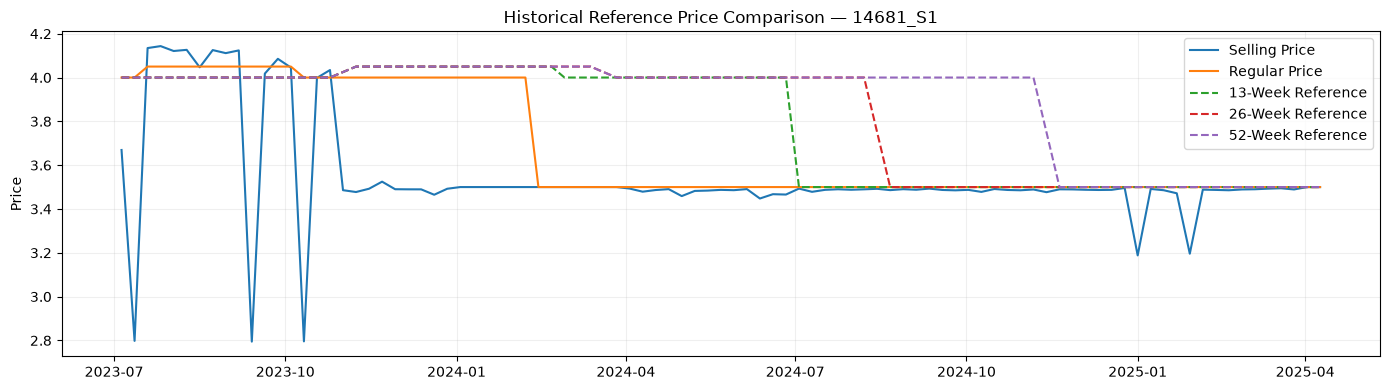

In [208]:
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(product.ds, product.sale_price, label="Selling Price")
ax.plot(product.ds, product.regular_price, label="Regular Price")

for window in [13, 26, 52]:
    reference = (
        product.regular_price.shift(H)
        .rolling(window, min_periods=1)
        .median()
        .fillna(product.regular_price.iloc[0])
    )

    ax.plot(product.ds, reference,
            label=f"{window}-Week Reference", linestyle="--")

ax.set_title(f"Historical Reference Price Comparison — {sku}")
ax.set_ylabel("Price")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Price index

The planned selling price over the reference price. It combines both ways a product can become cheaper than usual: a promotional discount, and a change in the regular price. A value of 0.75 means 25% below the product's normal price, whatever that price is.

In [209]:
panel["price_index"] = panel.planned_price / panel.price_reference

price_columns = ["regular_price", "sale_price", "rel_price", "promo", "discount", "planned_price", "price_reference", "price_index"]
panel.loc[(panel.unique_id == often_promoted) & panel.ds.between("2024-09-04", "2024-11-06"), ["ds", *price_columns]].round(3)

,ds,regular_price,sale_price,rel_price,promo,discount,planned_price,price_reference,price_index
2415,2024-09-04,5.0,4.500,0.900,1,0.100,4.500,5.0,0.900
2416,2024-09-11,5.0,4.500,0.900,1,0.100,4.500,5.0,0.900
2417,2024-09-18,5.0,4.500,0.900,1,0.100,4.500,5.0,0.900
2418,2024-09-25,5.0,4.500,0.900,1,0.100,4.500,5.0,0.900
2419,2024-10-02,5.0,4.478,0.896,1,0.104,4.478,5.0,0.896
2420,2024-10-09,5.0,4.479,0.896,1,0.104,4.479,5.0,0.896
2421,2024-10-16,5.0,4.473,0.895,1,0.105,4.473,5.0,0.895
2422,2024-10-23,5.0,4.488,0.898,1,0.102,4.488,5.0,0.898
2423,2024-10-30,5.0,4.488,0.898,1,0.102,4.488,5.0,0.898
2424,2024-11-06,5.0,4.469,0.894,1,0.106,4.469,5.0,0.894


Check: the code above produces exactly the columns of the shared `add_drivers`.

In [210]:
new_columns = ["rel_price", "promo", "discount", "planned_price", "price_reference", "price_index"]
shared_panel = add_drivers(panel.drop(columns=new_columns))
pd.testing.assert_frame_equal(panel, shared_panel, check_like=True)
print("price features match shared.features.add_drivers")

price features match shared.features.add_drivers


### How sales move with the discount

Promotion weeks grouped by discount depth. Sales are divided by the product's median sales in its non-promotion weeks, so a value of 2 means twice a normal week for that product, whatever its size. The line is the median across promotion weeks, the band the interquartile range.

This is an association, not a price elasticity. Retailers choose deeper discounts for products and seasons where they expect a big response, and promotions come with displays and advertising that the data does not record.

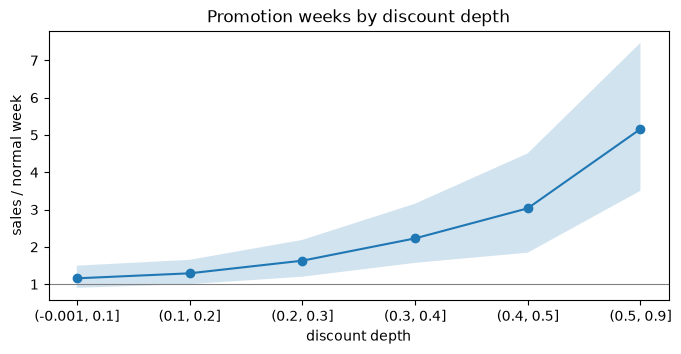

,weeks,q25,median,q75
discount,,,,
"(-0.001, 0.1]",6854,0.90,1.16,1.50
"(0.1, 0.2]",10197,1.00,1.29,1.65
"(0.2, 0.3]",7075,1.20,1.63,2.19
"(0.3, 0.4]",3930,1.57,2.23,3.16
"(0.4, 0.5]",1859,1.84,3.03,4.51
"(0.5, 0.9]",2798,3.50,5.16,7.47


In [211]:
past = panel[panel.ds <= TEST_CUTOFF].copy()
normal_sales = past[past.promo == 0].groupby("unique_id").y.median()
past["sales_vs_normal"] = past.y / past.unique_id.map(normal_sales.where(normal_sales > 0))

promotion_weeks = past[(past.promo == 1) & past.sales_vs_normal.notna()]
depth = pd.cut(promotion_weeks.discount, [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.9], include_lowest=True)
by_depth = promotion_weeks.groupby(depth, observed=True).sales_vs_normal
response = pd.DataFrame({"weeks": by_depth.size(), "q25": by_depth.quantile(0.25), "median": by_depth.median(), "q75": by_depth.quantile(0.75)})

fig, ax = plt.subplots(figsize=(8, 3.5))
labels = response.index.astype(str)
ax.plot(labels, response["median"], marker="o")
ax.fill_between(labels, response.q25, response.q75, alpha=0.2)
ax.axhline(1, color="grey", lw=0.8)
ax.set(xlabel="discount depth", ylabel="sales / normal week", title="Promotion weeks by discount depth")
plt.show()
response.round(2)

## 5. Promotion features

The promotion flag says whether a week is on promotion. The calendar features describe where the week sits in the sequence of promotions, which matters for demand:

- A recursive forecast sees last week's promotion spike in its sales lags and may carry it forward as if demand had risen. Knowing that last week was a promotion lets the model discount that spike.
- Customers who stock up during a promotion may buy less in the following weeks.
- A promotion after a long quiet period may draw a bigger response than one right after another promotion, when customers are still stocked up and less sensitive to the offer.

At week *t* each feature uses promotion flags up to week *t* only. For forecast weeks those flags come from the promotion plan. `promo_features` in `shared/features.py` builds the same columns.

- `promo_lag1`: Whether the product was on promotion one week ago.
- `promo_lag2`: Whether the product was on promotion two weeks ago.
- `promo_freq_13`: Proportion of the previous 13 weeks the product was on promotion.
- `weeks_since_promo`: Number of weeks since the last promotional week, capped at 26.
- `promo_x_gap`: When there is a promo, how long since the last promo. Interaction between the current promotion flag and weeks since the last promotion. Captures whether promotional lift depends on the spacing between promotions.

These features help the model learn the effects of promotion frequency, timing, and potential post-promotion changes in demand.

In [212]:
calendar = panel[["unique_id", "ds", "promo"]].copy()
promo_by_product = calendar.groupby("unique_id").promo

# promotion one and two weeks earlier: was last week's spike a promotion?
calendar["promo_lag1"] = promo_by_product.shift(1).fillna(0)
calendar["promo_lag2"] = promo_by_product.shift(2).fillna(0)

# share of the previous 13 weeks on promotion: how promotion-heavy the product has been lately
calendar["promo_freq_13"] = promo_by_product.transform(lambda flags: flags.shift(1).rolling(13, min_periods=1).mean()).fillna(0)

In [213]:
# Weeks since the previous promotion
last_promo = (
    calendar.ds.where(calendar.promo == 1)
    .groupby(calendar.unique_id).shift(1)
    .groupby(calendar.unique_id).ffill()
)

calendar["weeks_since_promo"] = (
    (calendar.ds - last_promo).dt.days / 7
).fillna(26).clip(upper=26)

# Promotional spacing interaction
calendar["promo_x_gap"] = (
    calendar["promo"] * calendar["weeks_since_promo"]
)

Weeks since the previous promotion: the date of the most recent promotion before this week, carried forward within the product. No promotion in the history counts as 26 weeks, and longer gaps are capped at 26, because a gap of half a year or more means "a long time" either way. The interaction is the gap in promotion weeks and 0 otherwise, so the model can give a promotion after a long gap a different lift from one right after another.

In [214]:
example_window = calendar[ calendar.ds.between("2024-09-04", "2024-11-06")]
promo_summary = (
    example_window.groupby("unique_id")["promo"]
    .agg(["sum", "count"]))

# Select products with 3–5 promotional weeks
example_id = promo_summary[
    promo_summary["sum"].between(3, 5)
    & (promo_summary["count"] == 10)
].index[0]

example_window[example_window.unique_id == example_id]

,unique_id,ds,promo,promo_lag1,promo_lag2,promo_freq_13,weeks_since_promo,promo_x_gap
810,10053_S1,2024-09-04,0,0.0,0.0,0.153846,6.0,0.0
811,10053_S1,2024-09-11,1,0.0,0.0,0.153846,7.0,7.0
812,10053_S1,2024-09-18,0,1.0,0.0,0.153846,1.0,0.0
813,10053_S1,2024-09-25,0,0.0,1.0,0.153846,2.0,0.0
814,10053_S1,2024-10-02,0,0.0,0.0,0.153846,3.0,0.0
815,10053_S1,2024-10-09,0,0.0,0.0,0.153846,4.0,0.0
816,10053_S1,2024-10-16,0,0.0,0.0,0.153846,5.0,0.0
817,10053_S1,2024-10-23,1,0.0,0.0,0.153846,6.0,6.0
818,10053_S1,2024-10-30,1,1.0,0.0,0.153846,1.0,1.0
819,10053_S1,2024-11-06,0,1.0,1.0,0.230769,1.0,0.0


### Sales before, during and after promotions

Sales relative to the product's normal week, by how many weeks a non-promotion week is before the next promotion (left) or after the last one (right). The dashed line is the median promotion week.

,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0
before,1.08,1.04,0.97,0.98,0.98,0.97,0.98,0.96
after,1.00,1.00,1.01,1.02,1.01,1.01,1.01,1.00


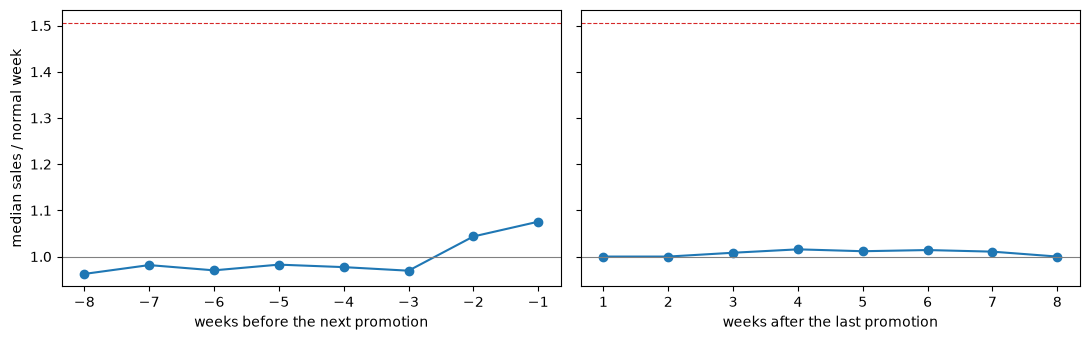

In [215]:
past = past.merge(calendar[["unique_id", "ds", "weeks_since_promo"]], on=["unique_id", "ds"])
next_promotion = past.ds.where(past.promo == 1).groupby(past.unique_id).shift(-1).groupby(past.unique_id).bfill()
past["weeks_to_promo"] = (next_promotion - past.ds).dt.days / 7

ordinary = past[(past.promo == 0) & past.sales_vs_normal.notna()]
before = ordinary[ordinary.weeks_to_promo <= 8].groupby("weeks_to_promo").sales_vs_normal.median()
after = ordinary[ordinary.weeks_since_promo <= 8].groupby("weeks_since_promo").sales_vs_normal.median()
promotion_median = promotion_weeks.sales_vs_normal.median()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
axes[0].plot(-before.index, before.values, marker="o")
axes[0].set(xlabel="weeks before the next promotion", ylabel="median sales / normal week")
axes[1].plot(after.index, after.values, marker="o")
axes[1].set(xlabel="weeks after the last promotion")
for ax in axes:
    ax.axhline(1, color="grey", lw=0.8)
    ax.axhline(promotion_median, color="tab:red", ls="--", lw=0.8)
plt.tight_layout()
pd.DataFrame({"before": before, "after": after}).round(2).T

### Does the gap since the previous promotion matter?

Promotion weeks grouped by the weeks since the previous promotion. The first group (1 week) is mostly the second and later weeks of multi-week promotions.

Can include multi-week promos

In [216]:
promotion_weeks = past[(past.promo == 1) & past.sales_vs_normal.notna()]
gap = pd.cut(promotion_weeks.weeks_since_promo, [0, 1, 4, 12, 25, 26], labels=["1", "2-4", "5-12", "13-25", "26+ or none"])
promotion_weeks.groupby(gap, observed=True).sales_vs_normal.agg(weeks="size", median="median").round(2)

,weeks,median
weeks_since_promo,,
1,18261,1.27
2-4,7635,2.32
5-12,4815,1.90
13-25,666,1.68
26+ or none,1336,1.58


### Promotional response differs across products

For each product with at least five promotion weeks, the median of its promotion weeks relative to its normal week. A global model has to learn this spread from the features and the product's history.

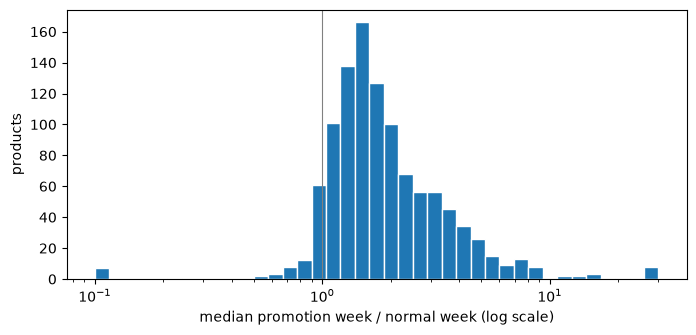

count    1075.00
mean        3.07
std        10.71
min         0.00
10%         1.07
25%         1.30
50%         1.70
75%         2.56
90%         4.08
max       196.00
Name: median, dtype: float64

In [217]:
lift = promotion_weeks.groupby("unique_id").sales_vs_normal.agg(["size", "median"])
lift = lift[lift["size"] >= 5]["median"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(lift.clip(0.1, 30), bins=np.geomspace(0.1, 30, 40), edgecolor="white")
ax.set_xscale("log")
ax.axvline(1, color="grey", lw=0.8)
ax.set(xlabel="median promotion week / normal week (log scale)", ylabel="products")
plt.show()
lift.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2)

## 6. Forecasting with future-driver visibility

### Static and dynamic features in MLForecast

MLForecast treats every column of the training frame other than `unique_id`, `ds` and `y` as a feature, and needs to know how each one behaves over time.

- **Static** features never change for a product: department, class and subclass. They go in `static_features` at fit time, and MLForecast repeats them for the forecast weeks.
- **Dynamic** features change from week to week: the promotion flag, the discount, prices. The model needs their values for every forecast week, passed to `predict` as `X_df`.

Any extra column not listed in `static_features` is dynamic. By default MLForecast treats every extra column as static, so always pass the list, `[]` if there are none.

The hierarchy ids are numbers in the data but they are labels, so they enter as pandas `category` columns and LightGBM splits on them as categories, never by size.

In [218]:
attributes.head(3)

,unique_id,department,class,subclass
0,10006_S1,108,117,1394
1,10008_S1,27,383,1402
2,10010_S1,12,226,1022


### One cutoff, no drivers yet: the static attributes

The training frame is the sales history up to the cutoff with the attributes merged on.

In [219]:
as_category = {col: "category" for col in CATEGORICAL}

train = actuals[actuals.ds <= TEST_CUTOFF].merge(attributes, on="unique_id").astype(as_category)
train.tail(3)

,unique_id,ds,y,department,class,subclass
185297,9985_S1,2025-03-26,1106.0,148,216,1021
185298,9985_S1,2025-04-02,1729.0,148,216,1021
185299,9985_S1,2025-04-09,987.0,148,216,1021


The model is the scaled baseline of notebook 02 (`lgbm_baseline`). `static_features` names the attribute columns; with no dynamic drivers, `predict` needs no `X_df`.

In [220]:
CATEGORICAL

['department', 'class', 'subclass']

In [221]:
attribute_model = MLForecast(
    models={"lgbm_categorical": lgb.LGBMRegressor(**LGB_PARAMS)},
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)
attribute_model.fit(train, static_features=CATEGORICAL)
attribute_model.predict(H).head(3)

,unique_id,ds,lgbm_categorical
0,10006_S1,2025-04-16,1737.741612
1,10006_S1,2025-04-23,1816.164537
2,10006_S1,2025-04-30,1820.660549


The features the model sees: the static attributes, then the lags, rolling means and calendar terms that MLForecast builds.

In [222]:
attribute_model.ts.features_order_

['department',
 'class',
 'subclass',
 'lag1',
 'lag2',
 'lag3',
 'lag4',
 'lag8',
 'lag13',
 'rolling_mean_lag1_window_size4',
 'rolling_mean_lag1_window_size13',
 'rolling_mean_lag1_window_size26',
 'month',
 'sin1',
 'cos1',
 'sin2',
 'cos2']

### Future Drivers as X_df 

For a retailer, every price and promotion column of sections 4 and 5 is known for the forecast weeks: it is the plan. The calendar features and the plan's price columns go into one frame, with a row for every product and week. 

In [223]:
plan_price_columns = ["discount", "price_index", "regular_price", "planned_price"]
plan_features = calendar.merge(panel[["unique_id", "ds", *plan_price_columns]], on=["unique_id", "ds"])
plan_features.head(3)

,unique_id,ds,promo,promo_lag1,promo_lag2,promo_freq_13,weeks_since_promo,promo_x_gap,discount,price_index,regular_price,planned_price
0,10006_S1,2023-07-05,0,0.0,0.0,0.0,26.0,0.0,0.0,1.0,2.95,2.95
1,10006_S1,2023-07-12,0,0.0,0.0,0.0,26.0,0.0,0.0,1.0,2.95,2.95
2,10006_S1,2023-07-19,0,0.0,0.0,0.0,26.0,0.0,0.0,1.0,2.95,2.95


### One cutoff with the plan

Take the promotion-calendar features, the discount and the price index. The training frame gets these columns for every week up to the cutoff, as well as the attributes:

In [224]:
promo_calendar_columns = ["promo", "promo_lag1", "promo_lag2", "promo_freq_13", "weeks_since_promo", "promo_x_gap"]
dynamic_columns = promo_calendar_columns + ["discount", "price_index"]

sales_to_cutoff = actuals[actuals.ds <= TEST_CUTOFF]
train = sales_to_cutoff.merge(plan_features[["unique_id", "ds", *dynamic_columns]], on=["unique_id", "ds"])
train = train.merge(attributes, on="unique_id").astype(as_category)
train.tail(3)

,unique_id,ds,y,promo,promo_lag1,promo_lag2,promo_freq_13,weeks_since_promo,promo_x_gap,discount,price_index,department,class,subclass
185297,9985_S1,2025-03-26,1106.0,0,0.0,0.0,0.307692,3.0,0.0,0.000000,1.000000,148,216,1021
185298,9985_S1,2025-04-02,1729.0,1,0.0,0.0,0.307692,4.0,4.0,0.270715,0.729285,148,216,1021
185299,9985_S1,2025-04-09,987.0,0,1.0,0.0,0.307692,1.0,0.0,0.000000,1.000000,148,216,1021


`X_df` holds the same dynamic columns for the 14 forecast weeks, one row per product and week. With a plan, they come straight from the plan. The static attributes are not in `X_df`; MLForecast repeats them itself.

In [225]:
forecast_end = TEST_CUTOFF + pd.Timedelta(weeks=H)
in_forecast_weeks = (plan_features.ds > TEST_CUTOFF) & (plan_features.ds <= forecast_end)
future_X_df = plan_features.loc[in_forecast_weeks,["unique_id", "ds"] + dynamic_columns]

print(f"{future_X_df.unique_id.nunique():,} products x {future_X_df.ds.nunique()} weeks, {future_X_df.ds.min():%Y-%m-%d} to {future_X_df.ds.max():%Y-%m-%d}")
future_X_df.head(3)

2,000 products x 14 weeks, 2025-04-16 to 2025-07-16


,unique_id,ds,promo,promo_lag1,promo_lag2,promo_freq_13,weeks_since_promo,promo_x_gap,discount,price_index
93,10006_S1,2025-04-16,0,0.0,0.0,0.153846,5.0,0.0,0.000000,1.000000
94,10006_S1,2025-04-23,1,0.0,0.0,0.153846,6.0,6.0,0.223644,0.776356
95,10006_S1,2025-04-30,0,1.0,0.0,0.230769,1.0,0.0,0.000000,1.000000


Same configuration as before. `fit` gets the frame with the dynamic columns and the list of static ones; `predict` gets `X_df`. Section 10 reuses this fitted model.

In [226]:
future_model = MLForecast(
    models={"lgbm_future_price_index": lgb.LGBMRegressor(**LGB_PARAMS)},
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)
future_model.fit(train, static_features=CATEGORICAL)
future_model.predict(H, X_df=future_X_df).head(3)

,unique_id,ds,lgbm_future_price_index
0,10006_S1,2025-04-16,1324.974851
1,10006_S1,2025-04-23,2681.470306
2,10006_S1,2025-04-30,1160.516046


### Feature sets

Each set adds one group to the set before it; the example above is the fourth. Section 8 uses the development origins to decide which groups earn their place.

incremental feature ablation experiment - testing the addition of 1 feature at a time.

In [227]:
feature_sets = {
    "lgbm_future_promo": ["promo"],
    "lgbm_future_promo_calendar": promo_calendar_columns,
    "lgbm_future_discount": promo_calendar_columns + ["discount"],
    "lgbm_future_price_index": promo_calendar_columns + ["discount", "price_index"],
    "lgbm_future_price_levels": promo_calendar_columns + ["discount", "price_index", "regular_price", "planned_price"],
}
pd.Series({name: ", ".join(cols) for name, cols in feature_sets.items()}, name="dynamic features").to_frame()

,dynamic features
lgbm_future_promo,promo
lgbm_future_promo_calendar,"promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap"
lgbm_future_discount,"promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount"
lgbm_future_price_index,"promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount, price_index"
lgbm_future_price_levels,"promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount, price_index, regular_price, planned_price"


## 7. Forecasting without future-driver visibility

A manufacturer forecasting what a retailer will sell usually does not see the retailer's promotion calendar or future prices. Price and promotion history can still help, as long as every value in `X_df` is known on the cutoff. A dynamic feature can be known for the forecast weeks in three ways:

| how it is known | example | scenario |
|---|---|---|
| it is lagged far enough | promotion 14 weeks earlier | no future visibility |
| we assume its future value | the regular price carried forward from the cutoff | no future visibility, with an assumption |
| a business plan gives it | the promotion calendar, the planned discount | future visibility |

A recursive 14-week forecast needs each driver for target weeks 1 to 14 after the cutoff. A driver lagged by *k* weeks is observed for target week *h* only if *k* is at least *h*: lag 1 exists for the first forecast week only, lag 14 for all 14. MLForecast fills its own sales lags with earlier forecasts, but it does not do that for drivers, so a short driver lag would need values nobody has.

In [228]:
horizons = [1, 2, 4, 8, 14]
pd.DataFrame({f"h={h}": ["observed" if k >= h else "unknown" for k in [1, 4, 13, 14]] for h in horizons},
             index=[f"promo lag {k}" for k in [1, 4, 13, 14]])

,h=1,h=2,h=4,h=8,h=14
promo lag 1,observed,unknown,unknown,unknown,unknown
promo lag 4,observed,observed,observed,unknown,unknown
promo lag 13,observed,observed,observed,observed,unknown
promo lag 14,observed,observed,observed,observed,observed


### A lagged promo feature

If future pricing isnt known, you can use lagged pricing features in your model.

In [229]:
history_features = panel[["unique_id", "ds", "regular_price"]].copy()
history_features["promo_lag14"] = panel.groupby("unique_id").promo.shift(H)

one_product = history_features.assign(promo=panel.promo)[history_features.unique_id == "10006_S1"].set_index("ds")
first_promo = one_product.index[one_product.promo == 1][0]
one_product.loc[first_promo - pd.Timedelta(weeks=1): first_promo + pd.Timedelta(weeks=15), ["promo", "promo_lag14"]]

,promo,promo_lag14
ds,,
2023-08-23,0,NaN
2023-08-30,1,NaN
2023-09-06,0,NaN
2023-09-13,0,NaN
2023-09-20,0,NaN
2023-09-27,0,NaN
2023-10-04,0,NaN
2023-10-11,0,0.0
2023-10-18,0,0.0


The promotion reappears in `promo_lag14` exactly 14 weeks later. At a cutoff, the forecast weeks run from 1 to 14 weeks ahead, so for each of them the week 14 weeks earlier is on or before the cutoff: the value is already known.

### A rolling feature

Shift first, then roll, so the window ends 14 weeks before the row's week. Rolling first would let the window reach into the forecast weeks.

In [230]:
promo_by_product = panel.promo.astype(float).groupby(panel.unique_id)
history_features["promo_share_26"] = promo_by_product.transform(lambda flags: flags.shift(H).rolling(26, min_periods=1).mean())
history_features[history_features.unique_id == "10006_S1"].iloc[40:44]

,unique_id,ds,regular_price,promo_lag14,promo_share_26
40,10006_S1,2024-04-10,2.95,0.0,0.115385
41,10006_S1,2024-04-17,2.95,0.0,0.115385
42,10006_S1,2024-04-24,2.95,0.0,0.115385
43,10006_S1,2024-05-01,2.95,0.0,0.115385


### The other historical drivers

All features are lagged by 14 weeks to avoid requiring future driver values.

- **weeks_since_promo_14:** Weeks since the last promotion as of 14 weeks ago (capped at 52).
- **rel_price_lag14:** Relative selling price 14 weeks ago.
- **discount_26:** Average discount depth over the previous 26 weeks.
- **rel_price_mean_13:** Average relative price over the previous 13 weeks.
- **rel_price_std_13:** Price variability over the previous 13 weeks.

All rolling windows end 14 weeks before the target week.

In [231]:
latest_promotion = panel.ds.where(panel.promo == 1).groupby(panel.unique_id).ffill()
latest_promotion_14_back = latest_promotion.groupby(panel.unique_id).shift(H)
history_features["weeks_since_promo_14"] = ((panel.ds - latest_promotion_14_back).dt.days / 7 - H).clip(upper=52).fillna(52)

rel_price_by_product = panel.rel_price.groupby(panel.unique_id)
history_features["rel_price_lag14"] = rel_price_by_product.shift(H)

discount_below_regular = (1 - panel.rel_price).clip(lower=0).groupby(panel.unique_id)
history_features["discount_26"] = discount_below_regular.transform(lambda d: d.shift(H).rolling(26, min_periods=1).mean())
history_features["rel_price_mean_13"] = rel_price_by_product.transform(lambda r: r.shift(H).rolling(13, min_periods=1).mean())
history_features["rel_price_std_13"] = rel_price_by_product.transform(lambda r: r.shift(H).rolling(13, min_periods=4).std())

The regular price is the current shelf price in the training rows. It is the one historical driver that needs an assumption for the forecast weeks, made when `X_df` is built below. 

In [232]:
historical_columns = ["promo_lag14", "promo_share_26", "weeks_since_promo_14", "rel_price_lag14", "discount_26",
                      "rel_price_mean_13", "rel_price_std_13", "regular_price"]
history_features = history_features[["unique_id", "ds", *historical_columns]]

history_features.dropna().head(3)

,unique_id,ds,promo_lag14,promo_share_26,weeks_since_promo_14,rel_price_lag14,discount_26,rel_price_mean_13,rel_price_std_13,regular_price
17,10006_S1,2023-11-01,0.0,0.0,52.0,0.990562,0.007753,0.992247,0.002827,2.95
18,10006_S1,2023-11-08,0.0,0.0,52.0,0.991288,0.007945,0.992055,0.002485,2.95
19,10006_S1,2023-11-15,0.0,0.0,52.0,0.996749,0.007163,0.992837,0.002935,2.95


### One cutoff without future visibility

The training frame, as before, with the historical columns:

In [233]:
as_category = {
    "department": "category",
    "class": "category",
    "subclass": "category"
}
train = sales_to_cutoff.merge(history_features, on=["unique_id", "ds"])
train = train.merge(attributes, on="unique_id").astype(as_category)
train.tail(3)

,unique_id,ds,y,promo_lag14,promo_share_26,weeks_since_promo_14,rel_price_lag14,discount_26,rel_price_mean_13,rel_price_std_13,regular_price,department,class,subclass
185297,9985_S1,2025-03-26,1106.0,0.0,0.307692,2.0,0.919012,0.204081,0.808590,0.132570,4.5,148,216,1021
185298,9985_S1,2025-04-02,1729.0,0.0,0.307692,3.0,0.945223,0.191711,0.808858,0.132865,4.5,148,216,1021
185299,9985_S1,2025-04-09,987.0,1.0,0.307692,0.0,0.761464,0.189972,0.818235,0.123923,4.5,148,216,1021


`X_df` takes the lagged columns for the forecast weeks as they are, because each already looks 14 weeks back. 

The regular price is the assumption: the last one observed on the cutoff, carried forward. Regular prices change in about 2% of weeks, so "no change" is usually right. Carrying the promotion flag forward would not be: promotions switch on and off.

In [234]:
in_forecast_weeks = (history_features.ds > TEST_CUTOFF) & (history_features.ds <= forecast_end)
history_X_df = history_features[in_forecast_weeks].copy()

last_regular_price = history_features[history_features.ds <= TEST_CUTOFF].groupby("unique_id").regular_price.last()
history_X_df["regular_price"] = history_X_df.unique_id.map(last_regular_price)

history_X_df[history_X_df.unique_id == "10006_S1"].head(4).round(3)     # every value observed on or before 2025-04-09

,unique_id,ds,promo_lag14,promo_share_26,weeks_since_promo_14,rel_price_lag14,discount_26,rel_price_mean_13,rel_price_std_13,regular_price
93,10006_S1,2025-04-16,0.0,0.115,5.0,0.995,0.042,0.958,0.092,2.95
94,10006_S1,2025-04-23,0.0,0.115,6.0,0.997,0.041,0.958,0.092,2.95
95,10006_S1,2025-04-30,0.0,0.115,7.0,0.975,0.041,0.973,0.074,2.95
96,10006_S1,2025-05-07,0.0,0.115,8.0,0.963,0.042,0.970,0.074,2.95


In [235]:
history_model = MLForecast(
    models={"lgbm_hist_drivers": lgb.LGBMRegressor(**LGB_PARAMS)},
    freq=FREQ,
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=DATE_FEATURES,
    target_transforms=[LocalStandardScaler()],
    num_threads=1,
)
history_model.fit(train, static_features=CATEGORICAL)
history_model.predict(H, X_df=history_X_df).head(3)

,unique_id,ds,lgbm_hist_drivers
0,10006_S1,2025-04-16,1734.722193
1,10006_S1,2025-04-23,1863.776136
2,10006_S1,2025-04-30,1828.807305


## 8. Every origin: what each feature group adds

The single-cutoff examples above, repeated at every cutoff on data up to that cutoff: the model without drivers, the five future feature sets and the historical drivers. `to_long` labels each forecast with the information it used. Seven models at ten origins, about two minutes.

In [236]:
forecasts = []

for cutoff in ALL_CUTOFFS:
    sales_to_cutoff = actuals[actuals.ds <= cutoff]
    forecast_end = cutoff + pd.Timedelta(weeks=H)

    # sales history, calendar and static attributes only
    train = sales_to_cutoff.merge(attributes, on="unique_id").astype(as_category)
    model = MLForecast(
        models={"lgbm_categorical": lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    model.fit(train, static_features=CATEGORICAL)
    forecasts.append(to_long(model.predict(H), cutoff, "03_exogenous", "history"))

    # full future visibility: the plan for every forecast week
    plan_weeks = (plan_features.ds > cutoff) & (plan_features.ds <= forecast_end)
    for name, columns in feature_sets.items():
        train = sales_to_cutoff.merge(plan_features[["unique_id", "ds", *columns]], on=["unique_id", "ds"])
        train = train.merge(attributes, on="unique_id").astype(as_category)
        X_df = plan_features.loc[plan_weeks, ["unique_id", "ds", *columns]]
        model = MLForecast(
            models={name: lgb.LGBMRegressor(**LGB_PARAMS)},
            freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
            target_transforms=[LocalStandardScaler()], num_threads=1,
        )
        model.fit(train, static_features=CATEGORICAL)
        forecasts.append(to_long(model.predict(H, X_df=X_df), cutoff, "03_exogenous", "future_drivers"))

    # no future visibility: lagged drivers, and the regular price carried forward from the cutoff
    train = sales_to_cutoff.merge(history_features, on=["unique_id", "ds"])
    train = train.merge(attributes, on="unique_id").astype(as_category)
    X_df = history_features[(history_features.ds > cutoff) & (history_features.ds <= forecast_end)].copy()
    last_regular_price = history_features[history_features.ds <= cutoff].groupby("unique_id").regular_price.last()
    X_df["regular_price"] = X_df.unique_id.map(last_regular_price)
    model = MLForecast(
        models={"lgbm_hist_drivers": lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    model.fit(train, static_features=CATEGORICAL)
    forecasts.append(to_long(model.predict(H, X_df=X_df), cutoff, "03_exogenous", "historical_drivers"))

forecasts = pd.concat(forecasts)

### Results

Development origins first, on rows every model forecasts, ordered by information and then WAPE. `lgbm_baseline` (notebook 02) is the same model without the static attributes. The rows use different information, so the table shows what each kind of information is worth; differences within a group isolate the features.

In [237]:
reference = load_forecasts(["02_ml_baseline"]).query("model == 'lgbm_baseline'")
candidates = pd.concat([reference, forecasts])
candidates["information_tier"] = candidates["information_tier"].replace(
    {"historical_only": "history"}
)
columns = ["model", "information", "wape", "bias", "mean_rmsse", "median_rmsse", "apc"]
leaderboard(candidates, actuals, scope="dev")[columns].sort_values("wape").round(3)

,model,information,wape,bias,mean_rmsse,median_rmsse,apc
3,lgbm_future_price_levels,Full future-driver visibility,0.311,0.069,1.658,0.749,0.131
4,lgbm_future_price_index,Full future-driver visibility,0.313,0.071,1.655,0.752,0.131
5,lgbm_future_discount,Full future-driver visibility,0.316,0.075,1.666,0.751,0.133
6,lgbm_future_promo_calendar,Full future-driver visibility,0.347,0.057,1.711,0.790,0.141
7,lgbm_future_promo,Full future-driver visibility,0.369,0.093,1.743,0.817,0.130
2,lgbm_hist_drivers,Historical exogenous features,0.416,0.091,1.837,0.884,0.149
0,lgbm_categorical,Sales history and calendar only,0.423,0.102,1.851,0.891,0.157
1,lgbm_baseline,Sales history and calendar only,0.449,0.139,1.865,0.921,0.136


In [238]:
pd.set_option("display.max_colwidth", None)

model_features = {
    "lgbm_baseline": [],
    "lgbm_categorical": CATEGORICAL,
    "lgbm_hist_drivers": CATEGORICAL + historical_columns,
}

model_features.update({
    name: CATEGORICAL + features
    for name, features in feature_sets.items()
})

pd.DataFrame([
    {
        "model": name,
        "n_exog": len(features),
        "exogenous_features": ", ".join(features) or "None"
    }
    for name, features in model_features.items()
])

,model,n_exog,exogenous_features
0,lgbm_baseline,0,None
1,lgbm_categorical,3,"department, class, subclass"
2,lgbm_hist_drivers,11,"department, class, subclass, promo_lag14, promo_share_26, weeks_since_promo_14, rel_price_lag14, discount_26, rel_price_mean_13, rel_price_std_13, regular_price"
3,lgbm_future_promo,4,"department, class, subclass, promo"
4,lgbm_future_promo_calendar,9,"department, class, subclass, promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap"
5,lgbm_future_discount,10,"department, class, subclass, promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount"
6,lgbm_future_price_index,11,"department, class, subclass, promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount, price_index"
7,lgbm_future_price_levels,13,"department, class, subclass, promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount, price_index, regular_price, planned_price"


### Which drivers earn their place

WAPE change in points at every origin: each future set against the set before it, the historical drivers against the model without drivers. A larger future set is chosen over the current one only if it lowers development WAPE by at least 0.2 points and wins at five or more of the seven development origins. The final window plays no part in the choice.

In [239]:
origins = list(DEV_CUTOFFS) + [TEST_CUTOFF]
by_origin = pd.concat([score(candidates[candidates.cutoff == c], actuals, rmsse=False).assign(cutoff=c.date()) for c in origins])
origin_wape = by_origin.pivot(index="model", columns="cutoff", values="wape")
dev_cols = [c.date() for c in DEV_CUTOFFS]

# each step against the model it extends
steps = ["lgbm_categorical"] + list(feature_sets)
compared_with = dict(zip(steps[1:], steps)) | {"lgbm_hist_drivers": "lgbm_categorical", "lgbm_categorical": "lgbm_baseline"}
change = pd.DataFrame({new: (origin_wape.loc[new] - origin_wape.loc[old]) * 100 for new, old in compared_with.items()}).T
change.insert(0, "against", pd.Series(compared_with))
change.assign(dev_mean=change[dev_cols].mean(axis=1), wins=(change[dev_cols] < 0).sum(axis=1)).round(2)

cutoff,against,2024-07-17,2024-08-14,2024-09-11,2024-10-09,2024-11-06,2024-12-04,2025-01-01,2025-04-09,dev_mean,wins
lgbm_future_promo,lgbm_categorical,-5.64,-4.47,-5.69,-5.68,-5.46,-5.76,-5.12,-6.07,-5.40,7
lgbm_future_promo_calendar,lgbm_future_promo,-1.66,-3.11,-1.66,-2.18,-2.01,-2.00,-2.71,-2.44,-2.19,7
lgbm_future_discount,lgbm_future_promo_calendar,-3.94,-2.45,-3.34,-3.17,-3.06,-2.96,-3.18,-3.99,-3.16,7
lgbm_future_price_index,lgbm_future_discount,0.82,-0.18,-0.38,-0.01,-1.03,-0.44,-0.37,0.10,-0.23,6
lgbm_future_price_levels,lgbm_future_price_index,-0.80,0.04,-0.09,-1.09,0.44,-0.08,-0.30,0.27,-0.27,5
lgbm_hist_drivers,lgbm_categorical,0.16,-0.66,-1.05,-1.53,-1.15,-1.33,0.22,-0.33,-0.76,5
lgbm_categorical,lgbm_baseline,-4.93,-2.20,-1.02,-1.33,-2.25,-3.15,-3.50,-1.94,-2.62,7


Only add features that provide meaningful and consistent improvements.

- Average WAPE reduction of at least 0.2 percentage points.
- Improved WAPE across at least 5 of 7 development cutoffs.

In [240]:
best_future = "lgbm_future_promo"
for name in list(feature_sets)[1:]:
    gain = (origin_wape.loc[best_future, dev_cols] - origin_wape.loc[name, dev_cols]) * 100
    if gain.mean() >= 0.2 and (gain > 0).sum() >= 5:
        best_future = name
print("chosen future-driver model:", best_future, "|", ", ".join(feature_sets[best_future]))

chosen future-driver model: lgbm_future_price_levels | promo, promo_lag1, promo_lag2, promo_freq_13, weeks_since_promo, promo_x_gap, discount, price_index, regular_price, planned_price


The final 14 weeks, an exploratory check (this window was inspected while the notebooks were built):

In [241]:
leaderboard(candidates, actuals, scope="test")[columns].sort_values("wape").round(3)

,model,information,wape,bias,mean_rmsse,median_rmsse,apc
3,lgbm_future_discount,Full future-driver visibility,0.274,0.049,1.148,0.572,0.096
4,lgbm_future_price_index,Full future-driver visibility,0.276,0.052,1.147,0.571,0.093
5,lgbm_future_price_levels,Full future-driver visibility,0.278,0.055,1.148,0.570,0.090
6,lgbm_future_promo_calendar,Full future-driver visibility,0.314,0.052,1.180,0.601,0.091
7,lgbm_future_promo,Full future-driver visibility,0.339,0.073,1.212,0.632,0.090
2,lgbm_hist_drivers,Historical exogenous features,0.396,0.107,1.266,0.711,0.111
0,lgbm_categorical,Sales history and calendar only,0.400,0.105,1.270,0.703,0.115
1,lgbm_baseline,Sales history and calendar only,0.419,0.109,1.302,0.733,0.101


lgbm_future_discount did not have these features:  price_index, regular_price, planned_price

### Key Findings

- **Item attributes:** 2.6-point WAPE improvement (7/7 wins).
- **Historical drivers:** 0.8-point improvement (5/7 wins).
- **Promotion flag:** 5.4-point improvement (7/7 wins).
- **Promotional calendar:** Additional 2.2 points (7/7 wins).
- **Discount depth:** Additional 3.2 points (7/7 wins).
- **Price index and price levels:** Marginal improvements.

**Takeaways:**
- Knowing promotion timing and discount depth provides the most value.
- Future drivers reduce WAPE from 42.3% to 31.1%.
- Future price levels from  initial autoregressive baseline 44.9% to 31.1%.
- Final-window results show similar improvements.
- Future-driver performance assumes perfect plan visibility.

## 9. Product-level investigations

The portfolio gain from the plan is an average over very different products. Four examples, chosen from the **development origins only**, among the top half of products by sales (smaller products swing on a handful of units):

- the product where the plan helps most;
- a product with promotions in its forecast windows where the plan changes little;
- the product where the plan hurts most;
- a product whose promotions vary most in discount depth.

"Helps" compares the mean absolute error of the chosen future-driver model with the same model without drivers (`lgbm_categorical`), over the seven development origins.

- Critical step in Real World Forecasting Production - identify the good/bad and discuss with the business.

In [242]:
compared_models = ["lgbm_categorical", "lgbm_hist_drivers", best_future]
development_rows = forecasts[forecasts.model.isin(compared_models) & forecasts.cutoff.isin(DEV_CUTOFFS)]
product_mae = score(development_rows, actuals, by=["unique_id"], rmsse=False).pivot(index="unique_id", columns="model", values="mae")
product_mae["error_change"] = product_mae[best_future] / product_mae["lgbm_categorical"] - 1     # negative: the plan helps

# promotions inside the development forecast windows, from the plan
in_development_windows = pd.concat([plan_features[(plan_features.ds > c) & (plan_features.ds <= c + pd.Timedelta(weeks=H))] for c in DEV_CUTOFFS])
promo_in_windows = in_development_windows.groupby("unique_id").promo.sum()
discount_spread = in_development_windows[in_development_windows.promo == 1].groupby("unique_id").discount.std()

sales_level = actuals[actuals.ds <= DEV_CUTOFFS[-1]].groupby("unique_id").y.mean()
large = product_mae.loc[sales_level[sales_level >= sales_level.median()].index]
with_promotions = large[promo_in_windows.reindex(large.index) >= 10]

examples = {
    "plan helps most": large.error_change.idxmin(),
    "plan changes little": with_promotions.error_change.abs().idxmin(),
    "plan hurts most": large.error_change.idxmax(),
}
spread = discount_spread.reindex(with_promotions.index).drop(list(examples.values()), errors="ignore")
examples["most varied discounts"] = spread.idxmax()

summary = pd.DataFrame({
    "product": examples,
    "mean_weekly_sales": {k: sales_level[p] for k, p in examples.items()},
    "promo_weeks_in_dev_windows": {k: promo_in_windows[p] for k, p in examples.items()},
    "mae_no_drivers": {k: product_mae.loc[p, "lgbm_categorical"] for k, p in examples.items()},
    "mae_hist_drivers": {k: product_mae.loc[p, "lgbm_hist_drivers"] for k, p in examples.items()},
    "mae_plan": {k: product_mae.loc[p, best_future] for k, p in examples.items()},
    "error_change": {k: product_mae.loc[p, "error_change"] for k, p in examples.items()},
})
summary.round(3)

,product,mean_weekly_sales,promo_weeks_in_dev_windows,mae_no_drivers,mae_hist_drivers,mae_plan,error_change
plan helps most,6276_S1,8122.215,13,8492.832,7840.879,1724.159,-0.797
plan changes little,3946_S1,3624.570,79,1788.183,1847.986,1788.488,0.000
plan hurts most,14801_S1,54763.671,95,8680.139,8298.628,13716.656,0.580
most varied discounts,17631_S1,1115.582,31,407.539,405.146,285.872,-0.299


Each example at the development cutoff with the most promotion weeks in its forecast window. Top: sales and the three forecasts. Middle: regular and planned selling price. Bottom: discount depth in promotion weeks. The dashed line is the cutoff.

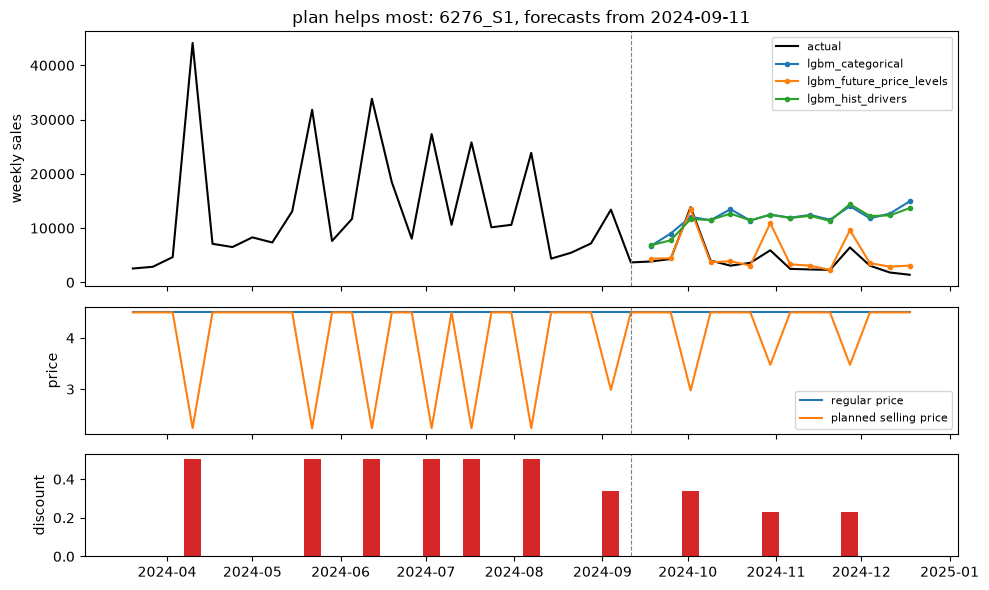

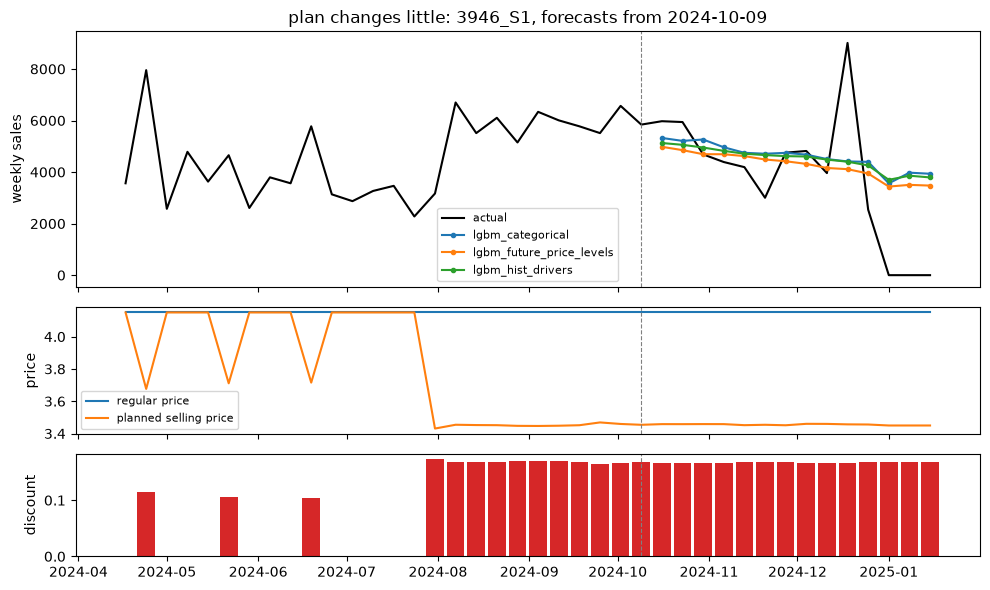

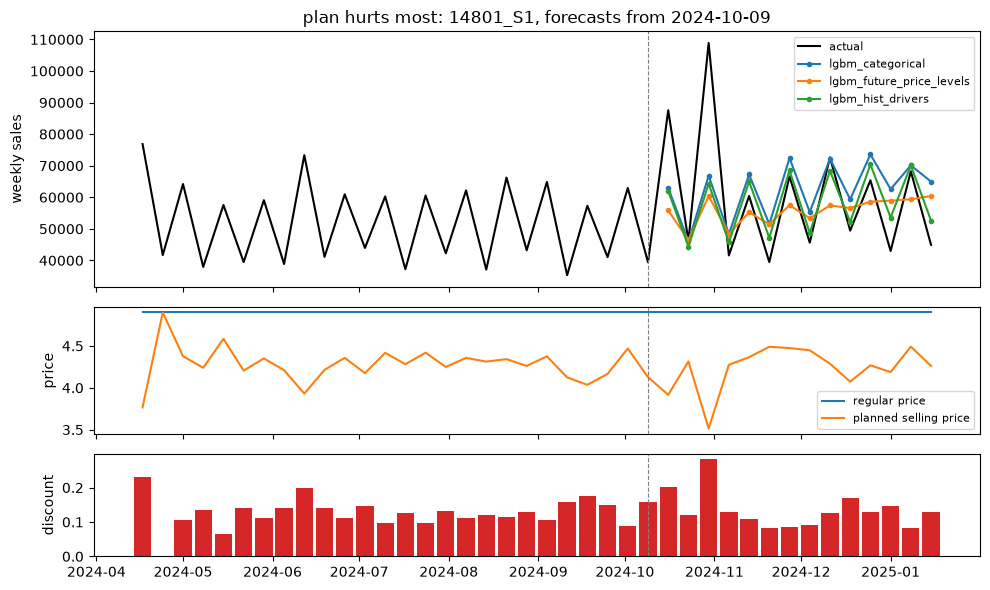

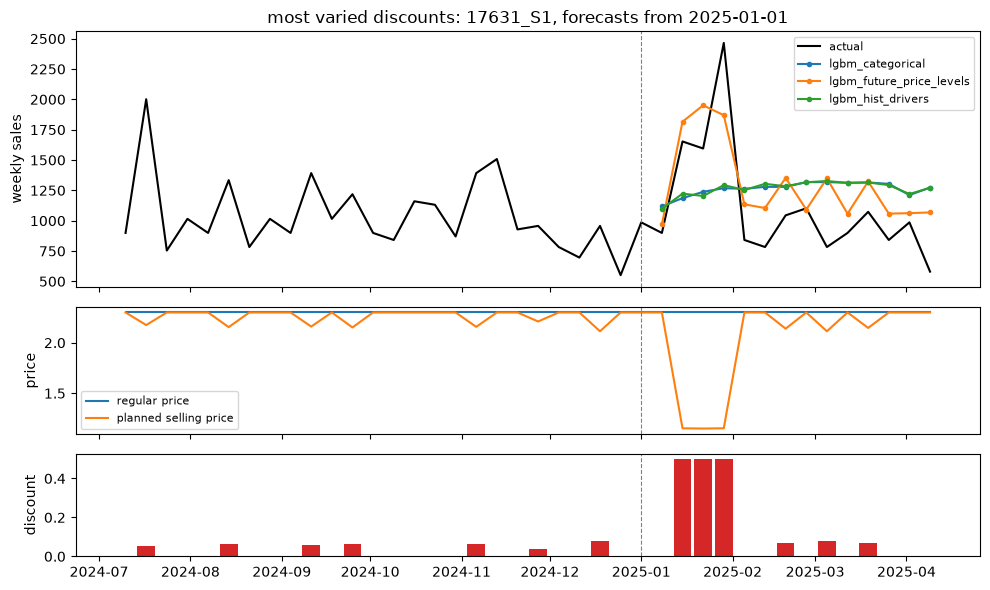

In [243]:
def plot_product(product, title):
    """Sales, forecasts, prices and discounts of one product around one development cutoff."""
    product_plan = plan_features[plan_features.unique_id == product]
    promotions_per_window = {c: product_plan[(product_plan.ds > c) & (product_plan.ds <= c + pd.Timedelta(weeks=H))].promo.sum() for c in DEV_CUTOFFS}
    cutoff = max(promotions_per_window, key=lambda c: (promotions_per_window[c], c))    # most promotions, latest on ties
    weeks = panel[(panel.unique_id == product) & (panel.ds > cutoff - pd.Timedelta(weeks=26)) & (panel.ds <= cutoff + pd.Timedelta(weeks=H))]
    shown = forecasts[(forecasts.unique_id == product) & (forecasts.cutoff == cutoff) & forecasts.model.isin(compared_models)]

    fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1, 0.8]})
    axes[0].plot(weeks.ds, weeks.y, color="black", label="actual")
    for model, rows in shown.groupby("model"):
        axes[0].plot(rows.ds, rows.yhat, marker=".", label=model)
    axes[0].set(title=f"{title}: {product}, forecasts from {cutoff:%Y-%m-%d}", ylabel="weekly sales")
    axes[0].legend(fontsize=8)
    axes[1].plot(weeks.ds, weeks.regular_price, label="regular price")
    axes[1].plot(weeks.ds, weeks.planned_price, label="planned selling price")
    axes[1].set_ylabel("price")
    axes[1].legend(fontsize=8)
    axes[2].bar(weeks.ds, weeks.discount, width=6, color="tab:red")
    axes[2].set_ylabel("discount")
    for ax in axes:
        ax.axvline(cutoff, color="grey", ls="--", lw=0.8)
    plt.tight_layout()
    plt.show()


for title, product in examples.items():
    plot_product(product, title)

RESULTS_PRODUCTS

## 10. How the model responds to a pricing scenario

A forecast with future drivers can be asked "what if?": change the planned discount and predict again. This reuses `future_model`, fitted in section 6 at the final cutoff with the promotion calendar, the discount and the price index. Nothing is retrained; only `X_df` changes.

The scenario keeps the promotion weeks of the plan and changes only their discount. The price index depends on the discount, so it is recomputed consistently: planned price = regular price x (1 - discount), price index = planned price / reference price. The calendar features depend only on the promotion flags, which do not change.

First, one high-volume product with a promotion planned in the first four forecast weeks.

In [244]:
scenario_base = future_X_df.merge(panel[["unique_id", "ds", "regular_price", "price_reference"]], on=["unique_id", "ds"])

early_promotions = scenario_base[(scenario_base.promo == 1) & (scenario_base.ds <= TEST_CUTOFF + pd.Timedelta(weeks=4))]
candidates_for_scenario = early_promotions[early_promotions.unique_id.isin(high_volume)]
scenario_product = candidates_for_scenario.unique_id.iloc[0]
scenario_week = candidates_for_scenario.ds.iloc[0]

product_history = panel[(panel.unique_id == scenario_product) & (panel.ds <= TEST_CUTOFF) & (panel.promo == 1)]
print(f"{scenario_product}, promotion week {scenario_week:%Y-%m-%d}, planned discount "
      f"{scenario_base.query('unique_id == @scenario_product and ds == @scenario_week').discount.iloc[0]:.2f}; "
      f"discounts seen in its history: {product_history.discount.min():.2f} to {product_history.discount.max():.2f}")

10010_S1, promotion week 2025-05-07, planned discount 0.04; discounts seen in its history: 0.00 to 0.12


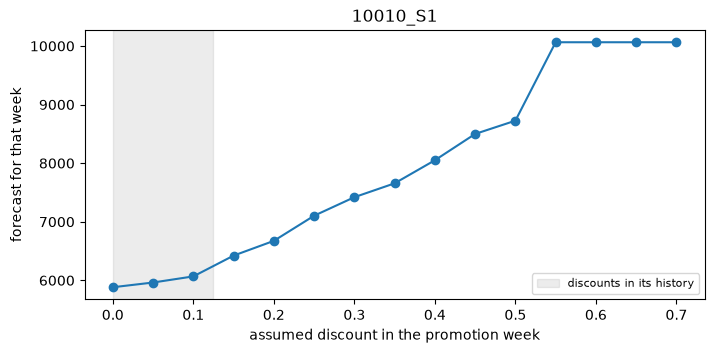

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
discount,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70
planned_price,6.60,6.27,5.94,5.61,5.28,4.95,4.62,4.29,3.96,3.63,3.30,2.97,2.64,2.31,1.98
forecast,5882.11,5962.86,6067.23,6421.87,6673.77,7102.40,7419.08,7655.77,8049.56,8498.59,8724.92,10063.64,10063.64,10063.64,10063.64


In [245]:
# Price Response and Implied Elasticity
discount_grid = np.round(np.arange(0, 0.71, 0.05), 2)
product_rows = scenario_base[scenario_base.unique_id == scenario_product]
scenario_forecasts = []

for discount in discount_grid:
    scenario = product_rows.copy()
    promotion_week = scenario.ds == scenario_week
    scenario.loc[promotion_week, "discount"] = discount
    planned_price = scenario.regular_price * (1 - scenario.discount)
    scenario["price_index"] = planned_price / scenario.price_reference

    prediction = future_model.predict(H, X_df=scenario[["unique_id", "ds", *dynamic_columns]], ids=[scenario_product])
    in_week = prediction[prediction.ds == scenario_week]["lgbm_future_price_index"].iloc[0]
    scenario_forecasts.append({"discount": discount, "planned_price": planned_price[promotion_week].iloc[0], "forecast": in_week})

scenario_forecasts = pd.DataFrame(scenario_forecasts)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(scenario_forecasts.discount, scenario_forecasts.forecast, marker="o")
ax.axvspan(product_history.discount.min(), product_history.discount.max(), color="grey", alpha=0.15, label="discounts in its history")
ax.set(xlabel="assumed discount in the promotion week", ylabel="forecast for that week", title=scenario_product)
ax.legend(fontsize=8)
plt.show()
scenario_forecasts.round(2).T

Then the whole portfolio: every promotion in the plan for the final window gets the same assumed discount, and the forecasts of the promotion weeks are summed. The ratio is against the forecast with the planned discounts.

In [246]:
# entire portfolio
planned_forecast = future_model.predict(H, X_df=future_X_df).merge(future_X_df[["unique_id", "ds", "promo"]], on=["unique_id", "ds"])
planned_total = planned_forecast.loc[planned_forecast.promo == 1, "lgbm_future_price_index"].sum()
portfolio = []

for discount in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    scenario = scenario_base.copy()
    scenario.loc[scenario.promo == 1, "discount"] = discount
    scenario["price_index"] = scenario.regular_price * (1 - scenario.discount) / scenario.price_reference

    prediction = future_model.predict(H, X_df=scenario[["unique_id", "ds", *dynamic_columns]])
    prediction = prediction.merge(scenario[["unique_id", "ds", "promo"]], on=["unique_id", "ds"])
    total = prediction.loc[prediction.promo == 1, "lgbm_future_price_index"].sum()
    portfolio.append({"discount": discount, "promotion_week_forecast_vs_plan": total / planned_total})

portfolio = pd.DataFrame(portfolio)
share_of_promotion_weeks = (scenario_base.promo == 1).mean()
print(f"planned promotion weeks: {share_of_promotion_weeks:.0%} of the forecast rows; "
      f"their median planned discount: {scenario_base.loc[scenario_base.promo == 1, 'discount'].median():.2f}")
portfolio.round(3).T

planned promotion weeks: 24% of the forecast rows; their median planned discount: 0.19


,0,1,2,3,4,5,6
discount,0.000,0.100,0.200,0.300,0.400,0.500,0.600
promotion_week_forecast_vs_plan,0.694,0.755,0.807,0.954,1.104,1.188,1.595


In [247]:
save_forecasts(forecasts, "03_exogenous")

## 11. Optional: Partial Plan Visibility

What if we only know the promotional plan for the next four weeks?

- **Weeks 1–4:** Use known price and promotion plans.
- **Weeks 5–14:** Assume no promotions, zero discounts and carry forward the last known regular price.
- Recalculate promotional calendar and pricing features.
- Keep the same model configuration and training data; only change the future inputs (`X_df`).

**Objective:** Measure the forecasting value of limited commercial plan visibility.

In [248]:
PLAN_WEEKS = 4
chosen_columns = feature_sets[best_future]
partial_forecasts = []

for cutoff in ALL_CUTOFFS:
    forecast_end = cutoff + pd.Timedelta(weeks=H)
    train = actuals[actuals.ds <= cutoff].merge(plan_features[["unique_id", "ds", *chosen_columns]], on=["unique_id", "ds"])
    train = train.merge(attributes, on="unique_id").astype(as_category)

    # the plan for the first PLAN_WEEKS weeks; after that no promotion at the cutoff's regular price
    partial = partial_plan(panel, cutoff, PLAN_WEEKS)
    X_df = partial.loc[(partial.ds > cutoff) & (partial.ds <= forecast_end), ["unique_id", "ds", *chosen_columns]]

    model = MLForecast(
        models={f"lgbm_partial_plan{PLAN_WEEKS}": lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    model.fit(train, static_features=CATEGORICAL)
    partial_forecasts.append(to_long(model.predict(H, X_df=X_df), cutoff, "03_exogenous", "partial_future_drivers"))

partial_forecasts = pd.concat(partial_forecasts)

In [249]:
partial_candidates = pd.concat([forecasts[forecasts.model.isin(["lgbm_categorical", "lgbm_hist_drivers", best_future])], partial_forecasts])
display(leaderboard(partial_candidates, actuals, scope="dev")[columns].round(3))
breakdown(partial_candidates, actuals, "horizon", scope="dev").pivot(index="horizon", columns="model", values="wape").round(3)

,model,information,wape,bias,mean_rmsse,median_rmsse,apc
0,lgbm_categorical,Sales history and calendar only,0.423,0.102,1.851,0.891,0.157
1,lgbm_hist_drivers,Historical exogenous features,0.416,0.091,1.837,0.884,0.149
2,lgbm_partial_plan4,Partial future-driver visibility,0.369,-0.057,1.778,0.840,0.235
3,lgbm_future_price_levels,Full future-driver visibility,0.311,0.069,1.658,0.749,0.131


model,lgbm_categorical,lgbm_future_price_levels,lgbm_hist_drivers,lgbm_partial_plan4
horizon,,,,
1,0.294,0.208,0.292,0.208
2,0.343,0.256,0.337,0.256
3,0.384,0.297,0.378,0.297
4,0.392,0.291,0.384,0.291
5,0.404,0.289,0.398,0.383
6,0.440,0.327,0.433,0.396
7,0.441,0.322,0.432,0.395
8,0.452,0.329,0.438,0.397
9,0.443,0.314,0.434,0.407


- In the four planned weeks the partial-plan forecast is the full-plan forecast (WAPE 0.208 to 0.291): same model, same `X_df`.
- From week 5 it assumes no promotions and drifts toward the model without drivers: 0.383 in week 5 against 0.289 with the full plan and 0.404 without drivers.
- Over all 14 weeks: 0.369 on development, between the historical drivers (0.416) and the full plan (0.311).
- It underforecasts (bias -0.057): trained on history where promotions are known, then told there are none, it forecasts demand without the lifts that do happen. It also revises the most between origins (APC 0.235), because weeks 5 to 8 of one forecast move from "no promotion" to the plan in the next.

Try it later: set `PLAN_WEEKS` to 8.

In [250]:
save_forecasts(partial_forecasts, "03_partial_plan")

## 12. Optional: leakage diagnostics for Day 2 comparisons

`sale_price` is a realized average selling price. A week with no sales has no transactions to average, so it gets the regular price: outside promotions, the realized price reveals which weeks sold nothing. It is derived from the target, not a plan, which is why `discount` (section 4) takes the selling price from promotion weeks only.

The Day 2 neural models use covariates built from this realized price, so Day 1 keeps two models with the same information, for a like-for-like comparison:

- `lgbm_realized_price_leaky`: the promotion-calendar features, with discount and price index computed from the realized selling price in every week;
- `lgbm_day2_covariates_leaky`: the promotion-calendar features with Day 2's `discount_depth` and `price_index`.

Both are labeled `leakage_diagnostic`. They are never candidates for model selection or ensembles (notebook 07), and notebook 08 reports them separately. Same model setup as section 8; the code is in `shared/diagnostics.py`. About a minute.

In [251]:
from shared.diagnostics import leakage_diagnostics

leak_forecasts = leakage_diagnostics(panel, ALL_CUTOFFS)

Against the planned-price model and the model without drivers. Development origins, then the final window; the last columns split the development rows by whether the target week turned out to have zero sales (MAE, because WAPE is undefined for weeks with no sales).

In [252]:
leak_candidates = pd.concat([forecasts[forecasts.model.isin(["lgbm_categorical", best_future])], leak_forecasts])
dev = leaderboard(leak_candidates, actuals, scope="dev").set_index("model")
final = leaderboard(leak_candidates, actuals, scope="test").set_index("model")

rows = leak_candidates[leak_candidates.cutoff.isin(DEV_CUTOFFS)].merge(actuals.assign(zero_week=actuals.y == 0)[["unique_id", "ds", "zero_week"]], on=["unique_id", "ds"])
split = score(rows, actuals, by=["zero_week"], rmsse=False).pivot(index="model", columns="zero_week", values="mae")
split.columns = ["mae_selling_weeks", "mae_zero_weeks"]
pd.concat([dev[["information", "wape", "bias", "mean_rmsse"]], final[["wape", "bias"]].add_prefix("final_"), split], axis=1).round(3)

,information,wape,bias,mean_rmsse,final_wape,final_bias,mae_selling_weeks,mae_zero_weeks
model,,,,,,,,
lgbm_categorical,Sales history and calendar only,0.423,0.102,1.851,0.400,0.105,1808.131,1614.536
lgbm_future_price_levels,Full future-driver visibility,0.311,0.069,1.658,0.278,0.055,1283.706,1410.330
lgbm_day2_covariates_leaky,Leakage diagnostic,0.270,0.035,1.572,0.254,0.036,1118.731,1214.266
lgbm_realized_price_leaky,Leakage diagnostic,0.291,0.081,1.569,0.282,0.098,1230.079,1169.330


- **Both diagnostics beat the planned-price model** on development: 0.270 with the Day 2 covariates and 0.291 with the realized price, against 0.311. In the final window the Day 2 covariates give 0.254 against 0.278.
- **The realized price reveals the zero-sales weeks.** `lgbm_realized_price_leaky` has the lowest error of the four in weeks that turned out to sell nothing (MAE 1,169 against 1,410 for the plan).
- So a Day 2 model whose covariates come from the realized price compares with `lgbm_day2_covariates_leaky` (0.254 in the final window), not with the planned-price model (0.278). The gap is information that does not exist on the forecast date.

In [253]:
save_forecasts(leak_forecasts, "03_leakage_diagnostics")